<a href="https://colab.research.google.com/github/JEANWitchLeyder/house_price_prediction/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_NUM_INTRAOP_THREADS'] = '2'
os.environ['TF_NUM_INTEROP_THREADS'] = '2'
import sys, json, platform, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from IPython.display import display
SEED = 42
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
versions = dict(python=platform.python_version(), tensorflow=tf.__version__,
                keras=keras.__version__, numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__)
import matplotlib, joblib
versions.update(matplotlib=matplotlib.__version__, joblib=joblib.__version__)
print(versions)
# A small thread pool keeps CPU use predictable on student laptops.
def batches(x, y, size, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(size).with_options(options).prefetch(1)

OUT = Path('artifacts/house'); OUT.mkdir(parents=True, exist_ok=True)
(OUT/'versions.json').write_text(json.dumps(versions, indent=2))

{'python': '3.13.16', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'matplotlib': '3.10.0', 'joblib': '1.6.0'}


182

In [3]:
from urllib.request import urlopen
DATA_URL = 'https://jse.amstat.org/v19n3/decock/AmesHousing.txt'
LOCAL_DATA_PATH = Path('data/AmesHousing.txt')  # Change to your .txt or .csv file.
if not LOCAL_DATA_PATH.exists():
    LOCAL_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    try:
        with urlopen(DATA_URL, timeout=60) as response:
            LOCAL_DATA_PATH.write_bytes(response.read())
    except Exception as exc:
        raise RuntimeError('Download failed. Download AmesHousing.txt from the cited source, '
                           'upload it to data/, or set LOCAL_DATA_PATH to a local CSV.') from exc
raw = pd.read_csv(LOCAL_DATA_PATH, sep=',' if LOCAL_DATA_PATH.suffix.lower()=='.csv' else '\t')
raw.columns = raw.columns.str.strip()
NUM = ['Gr Liv Area', 'TotRms AbvGrd', 'Full Bath', 'Half Bath',
       'Year Built', 'Overall Qual', 'Garage Cars']
CAT = ['Neighborhood']
FEATURES = NUM + CAT
TARGET = 'SalePrice'
assert set(FEATURES + [TARGET]).issubset(raw.columns), 'Incorrect dataset schema'
print('Raw shape:', raw.shape)
print('Exact full-row duplicates:', raw.duplicated().sum())
raw = raw.drop_duplicates().copy()
# Do not discard distinct houses just because selected features happen to match.
if 'PID' in raw:
    assert raw['PID'].notna().all() and raw['PID'].is_unique, 'Repeated parcel: use a group split'
y_raw = pd.to_numeric(raw[TARGET], errors='coerce')
valid_target = y_raw.notna() & np.isfinite(y_raw) & (y_raw > 0)
print('Excluded missing/invalid targets:', int((~valid_target).sum()))
raw = raw.loc[valid_target].copy()
raw[TARGET] = y_raw.loc[valid_target]
for column in NUM:
    raw[column] = pd.to_numeric(raw[column], errors='raise')
    assert not np.isinf(raw[column].dropna()).any()
X, y = raw[FEATURES].copy(), raw[TARGET].astype(float)
# 70% train / 15% validation / 15% test, split before exploration or fitting.
X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=0.50, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))
np.savez(OUT/'split_indices.npz', train=X_train.index, validation=X_val.index, test=X_test.index)
(OUT/'data_source.json').write_text(json.dumps(dict(url=DATA_URL,
    sha256=hashlib.sha256(LOCAL_DATA_PATH.read_bytes()).hexdigest(), rows=len(raw)), indent=2))

Raw shape: (2930, 82)
Exact full-row duplicates: 0
Excluded missing/invalid targets: 0
Train / validation / test: 2051 439 440


162

,missing training values
Gr Liv Area,0
TotRms AbvGrd,0
Full Bath,0
Half Bath,0
Year Built,0
Overall Qual,0
Garage Cars,1
Neighborhood,0


,Gr Liv Area,TotRms AbvGrd,Full Bath,Half Bath,Year Built,Overall Qual,Garage Cars,Neighborhood
count,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2051.000000,2050.000000,2051
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NAmes
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,322
mean,1497.625061,6.428084,1.559727,0.367626,1969.984398,6.054120,1.748293,NaN
std,514.943178,1.592382,0.554992,0.500151,30.401103,1.393538,0.752455,NaN
min,334.000000,2.000000,0.000000,0.000000,1872.000000,1.000000,0.000000,NaN
25%,1121.000000,5.000000,1.000000,0.000000,1953.000000,5.000000,1.000000,NaN
50%,1440.000000,6.000000,2.000000,0.000000,1972.000000,6.000000,2.000000,NaN
75%,1741.000000,7.000000,2.000000,1.000000,1999.000000,7.000000,2.000000,NaN


Matching selected-feature rows in training: 60


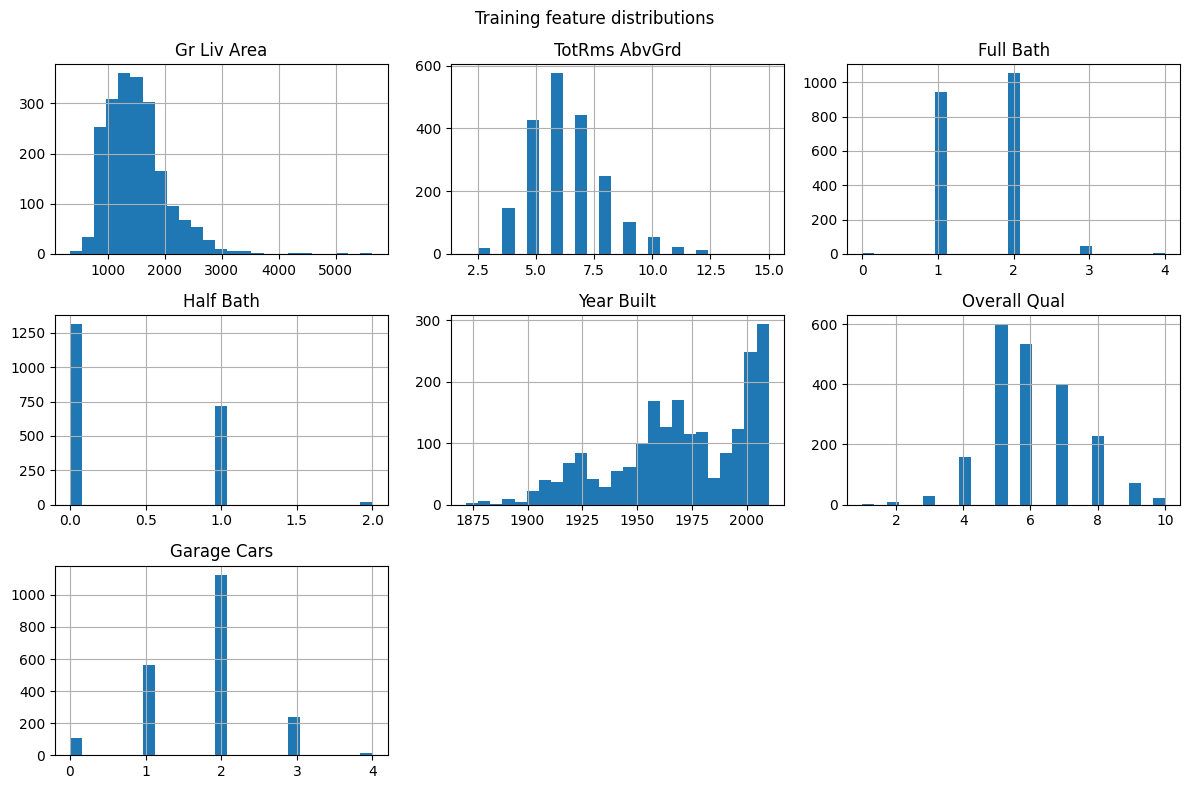

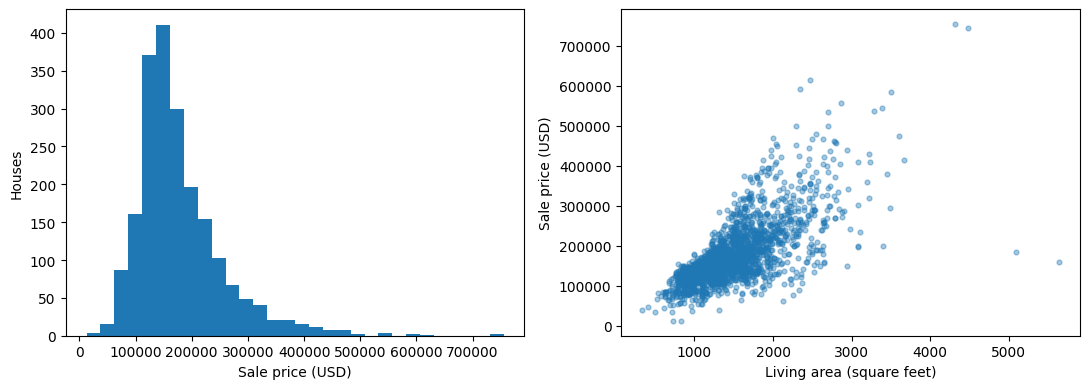

In [4]:
display(X_train.isna().sum().rename('missing training values').to_frame())
display(X_train.describe(include='all'))
print('Matching selected-feature rows in training:', X_train.duplicated().sum())
X_train[NUM].hist(figsize=(12, 8), bins=25)
plt.suptitle('Training feature distributions'); plt.tight_layout()
plt.savefig(OUT/'feature_distributions.png'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y_train, bins=30); axes[0].set(xlabel='Sale price (USD)', ylabel='Houses')
axes[1].scatter(X_train['Gr Liv Area'], y_train, alpha=.4, s=12)
axes[1].set(xlabel='Living area (square feet)', ylabel='Sale price (USD)')
plt.tight_layout(); plt.savefig(OUT/'target_distribution.png'); plt.show()

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM),
    ('category', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                           ('encode', OneHotEncoder(handle_unknown='ignore', drop='first',
                                                    sparse_output=False))]), CAT)
])
assert X_train.notna().any().all(), 'A training column is entirely missing'
a_train = preprocessor.fit_transform(X_train).astype('float32')
a_val = preprocessor.transform(X_val).astype('float32')
assert a_train.shape[1] == a_val.shape[1]
assert np.isfinite(a_train).all() and np.isfinite(a_val).all()
PRICE_SCALE = 100_000.0
t_train = (y_train.to_numpy()/PRICE_SCALE).astype('float32')
t_val = (y_val.to_numpy()/PRICE_SCALE).astype('float32')
print('Encoded input shape:', a_train.shape)

Encoded input shape: (2051, 34)


In [7]:
baseline = LinearRegression()
baseline.fit(a_train, t_train)
keras.utils.set_random_seed(SEED)
model = keras.Sequential([
    keras.layers.Input(shape=(a_train.shape[1],)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1)  # linear output
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,665 (6.50 KB)

 Trainable params: 1,665 (6.50 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 75
Best validation epoch: 55


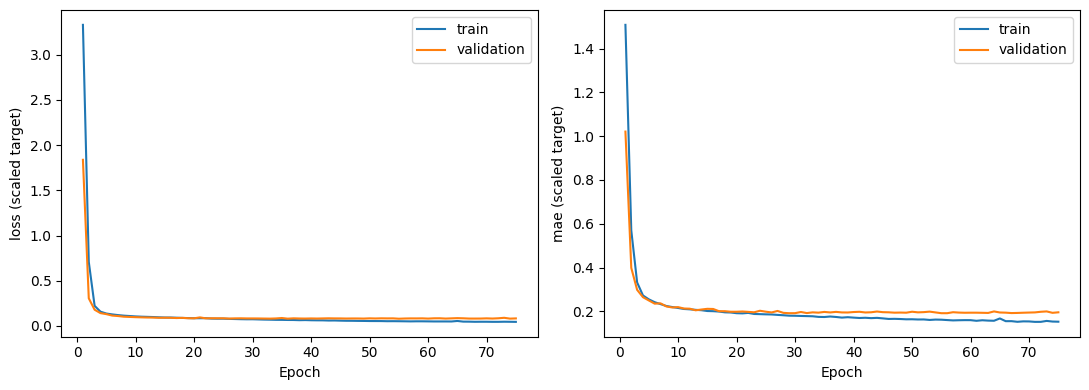

Linear validation MAE (USD): 21787.666948809438
Dense validation MAE (USD): 19165.343687713554


In [8]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
history = model.fit(batches(a_train, t_train, 32, True),
                    validation_data=batches(a_val, t_val, 32), epochs=200,
                    callbacks=[early_stop, keras.callbacks.TerminateOnNaN()], verbose=0)
print('Epochs run:', len(history.history['loss']))
print('Best validation epoch:', int(np.argmin(history.history['val_loss'])+1))
assert np.isfinite(history.history['loss']).all()
pd.DataFrame(history.history).to_csv(OUT/'training_history.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, ax in zip(['loss', 'mae'], axes):
    ax.plot(np.arange(1,len(history.history[key])+1), history.history[key], label='train')
    ax.plot(np.arange(1,len(history.history[key])+1), history.history['val_'+key], label='validation')
    ax.set(xlabel='Epoch', ylabel=key+' (scaled target)'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png'); plt.show()
# Validation-only comparison before opening the test set.
for name, pred in [('Linear', baseline.predict(a_val)), ('Dense', model(a_val, training=False).numpy().ravel())]:
    print(name, 'validation MAE (USD):', mean_absolute_error(y_val, pred*PRICE_SCALE))

Linear regression negative predictions: 0
Dense neural network negative predictions: 0


,MAE_USD,RMSE_USD,R2
model,,,
Linear regression,22575.868,37996.411,0.800
Dense neural network,20209.705,32394.629,0.854


Linear regression: average absolute error = USD 22,575.87
Dense neural network: average absolute error = USD 20,209.70
Lower test MAE in this fixed comparison: Dense neural network
This comparison is descriptive; do not retune using it.


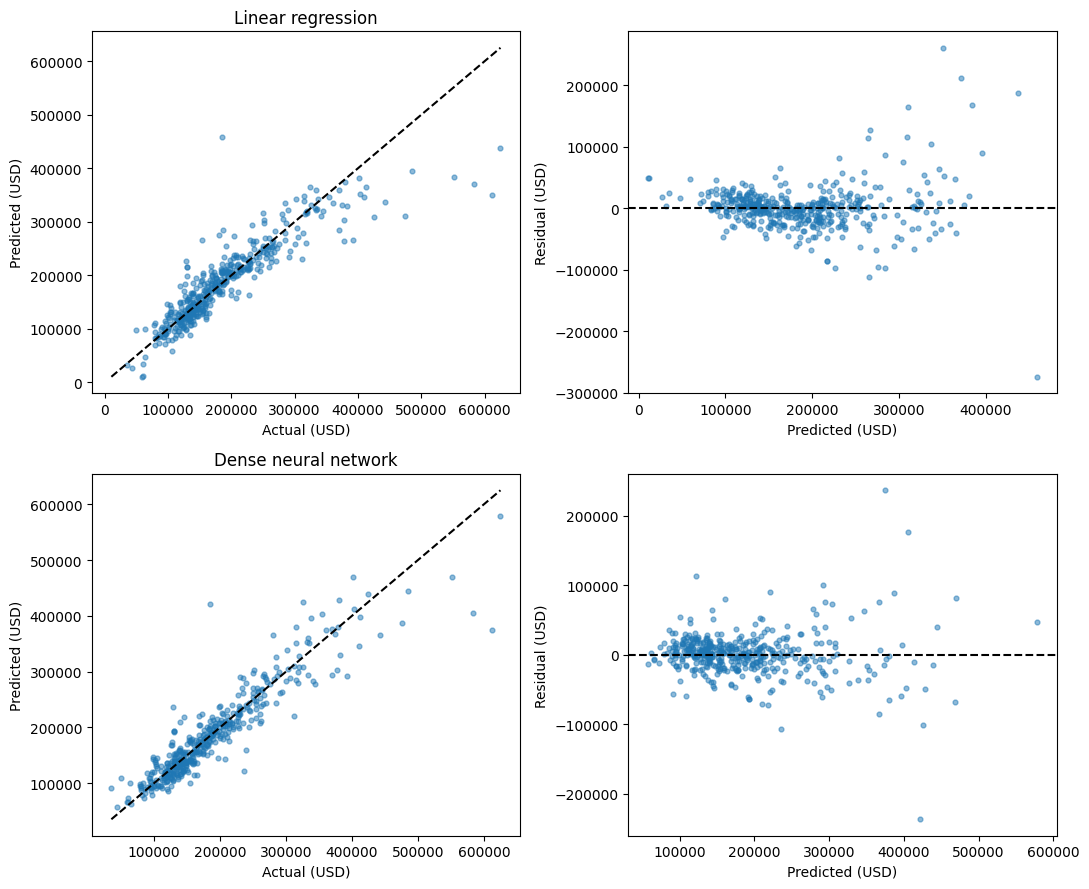

In [9]:
a_test = preprocessor.transform(X_test).astype('float32')
assert a_test.shape[1] == a_train.shape[1] and np.isfinite(a_test).all()
predictions = {'Linear regression': baseline.predict(a_test)*PRICE_SCALE,
               'Dense neural network': model(a_test, training=False).numpy().ravel()*PRICE_SCALE}
rows = []
for name, pred in predictions.items():
    assert pred.shape == y_test.shape and np.isfinite(pred).all()
    rows.append(dict(model=name, MAE_USD=mean_absolute_error(y_test,pred),
                     RMSE_USD=np.sqrt(mean_squared_error(y_test,pred)), R2=r2_score(y_test,pred)))
    print(name, 'negative predictions:', int((pred<0).sum()))
results = pd.DataFrame(rows).set_index('model')
display(results.round(3)); results.to_csv(OUT/'test_metrics.csv')
for name in results.index:
    print(f"{name}: average absolute error = USD {results.loc[name, 'MAE_USD']:,.2f}")
print('Lower test MAE in this fixed comparison:', results.MAE_USD.idxmin())
print('This comparison is descriptive; do not retune using it.')
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (name, pred) in enumerate(predictions.items()):
    lo, hi = min(y_test.min(),pred.min()), max(y_test.max(),pred.max())
    axes[row,0].scatter(y_test, pred, s=12, alpha=.5)
    axes[row,0].plot([lo,hi],[lo,hi],'k--')
    axes[row,0].set(title=name, xlabel='Actual (USD)', ylabel='Predicted (USD)')
    axes[row,1].scatter(pred, y_test-pred, s=12, alpha=.5)
    axes[row,1].axhline(0, color='black', linestyle='--')
    axes[row,1].set(xlabel='Predicted (USD)', ylabel='Residual (USD)')
plt.tight_layout(); plt.savefig(OUT/'test_diagnostics.png'); plt.show()
pd.DataFrame({'actual_USD': y_test, **predictions}).to_csv(OUT/'test_predictions.csv')

In [10]:
new_house = pd.DataFrame([{'Gr Liv Area':1800, 'TotRms AbvGrd':7, 'Full Bath':2,
    'Half Bath':1, 'Year Built':2000, 'Overall Qual':7, 'Garage Cars':2, 'Neighborhood':'CollgCr'}])
new_house = new_house.loc[:, FEATURES]
assert new_house.shape == (1, len(FEATURES)) and not new_house.isna().any().any()
new_array = preprocessor.transform(new_house).astype('float32')
new_price = float(model(new_array, training=False).numpy().ravel()[0]*PRICE_SCALE)
assert np.isfinite(new_price)
print(f'Illustrative house prediction: USD {new_price:,.2f}')

Illustrative house prediction: USD 207,256.98


In [11]:
model.save(OUT/'house_model.keras')
joblib.dump(preprocessor, OUT/'preprocessor.joblib')
joblib.dump(baseline, OUT/'linear_baseline.joblib')
(OUT/'schema.json').write_text(json.dumps(dict(features=FEATURES, price_scale=PRICE_SCALE,
                                             currency='USD', period='2006-2010'), indent=2))
loaded = keras.models.load_model(OUT/'house_model.keras')
loaded_preprocessor = joblib.load(OUT/'preprocessor.joblib')
loaded_baseline = joblib.load(OUT/'linear_baseline.joblib')
schema = json.loads((OUT/'schema.json').read_text())
loaded_array = loaded_preprocessor.transform(new_house.loc[:,schema['features']]).astype('float32')
reloaded_price = loaded(loaded_array, training=False).numpy().ravel()*schema['price_scale']
assert np.isfinite(reloaded_price).all()
np.testing.assert_allclose(reloaded_price, [new_price], rtol=1e-5, atol=.05)
np.testing.assert_allclose(loaded_baseline.predict(loaded_array), baseline.predict(new_array), rtol=1e-6)
print('Reload checks passed. Price (USD):', reloaded_price[0])

Reload checks passed. Price (USD): 207256.98


**References**

- **Dataset paper:** [De Cock (2011), Ames, Iowa](https://doi.org/10.1080/10691898.2011.11889627), Journal of Statistics Education 19(3), DOI 10.1080/10691898.2011.11889627. Accessible original paper establishes provenance, period and unusual-sale concerns; it does not establish that neural networks outperform linear models.
- **Original housing data:** [AmesHousing.txt](https://jse.amstat.org/v19n3/decock/AmesHousing.txt) and [variable documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt).
- **Original MNIST source:** [LeCun, Cortes and Burges](http://yann.lecun.com/exdb/mnist/). Homepage inaccessible in this review; the accessible [official Keras dataset documentation](https://keras.io/api/datasets/mnist/) verifies shapes, counts, labels and loading API. MNIST derives from NIST handwriting data.
- **Tutorials, not research papers:** TensorFlow [basic regression](https://www.tensorflow.org/tutorials/keras/regression) and [beginner MNIST quickstart](https://www.tensorflow.org/tutorials/quickstart/beginner). These inform the Sequential/compile/fit workflow; their published example scores are not our results.
- **API/method documentation:** [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), [Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/), [Keras saving](https://keras.io/guides/serialization_and_saving/). These inform train-only fitting, best-weight restoration and `.keras` persistence.


